 **Load the Data**

We will bring in the loan applicant data.
This data has details like income, age, and loan amount.
It also tells us who repaid and who defaulted.

In [179]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [180]:
df = pd.read_csv('credit_risk_dataset.csv')
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


**Exploratory Data Analysis (EDA)**

Here we simply look at the data before touching it.
We want to understand it first, then work on it.

Basic info about the data

Check how many rows and columns we have.
Check the data type of each column.

In [181]:
df.shape
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB
None


**Missing values**

Find out which columns have empty or missing values.
This tells us where we may need to fix things later.

In [182]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


**Target balance**

Check how many people defaulted vs how many repaid.
This tells us if our data is balanced or imbalanced.

In [183]:
df.head()
df['loan_status'].unique()
df['loan_status'].value_counts()

,count
loan_status,
0,25473
1,7108


<Axes: xlabel='loan_status', ylabel='count'>

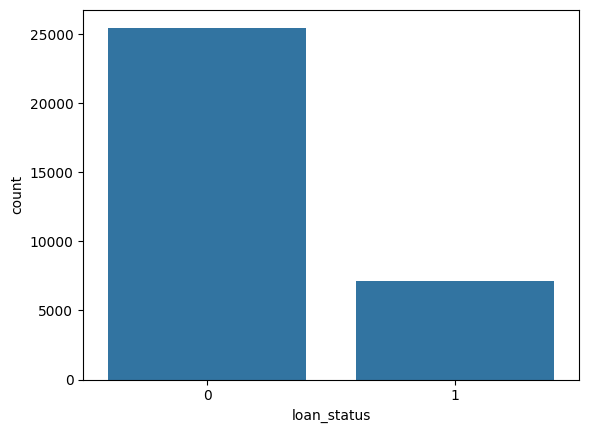

In [184]:
sns.countplot(x=df['loan_status'])

**Outlier check**

Look for values that seem impossible, like age 144.
These are signs of bad data entries.

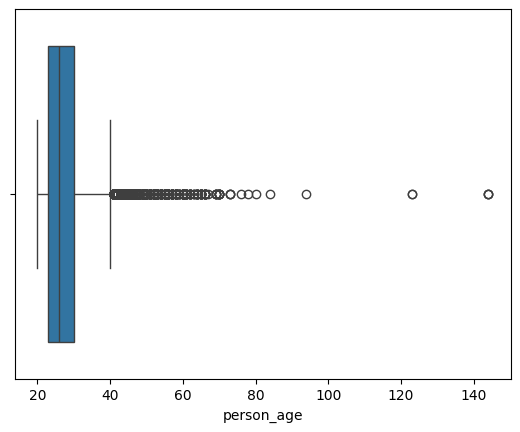

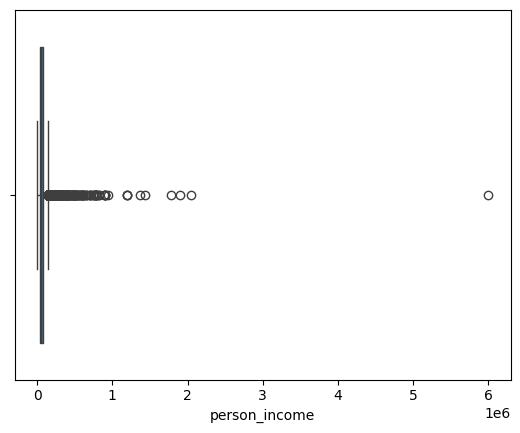

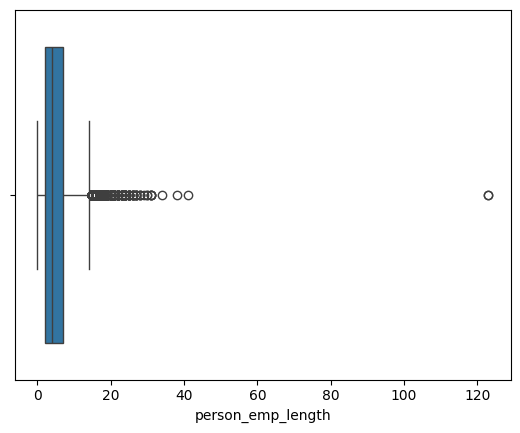

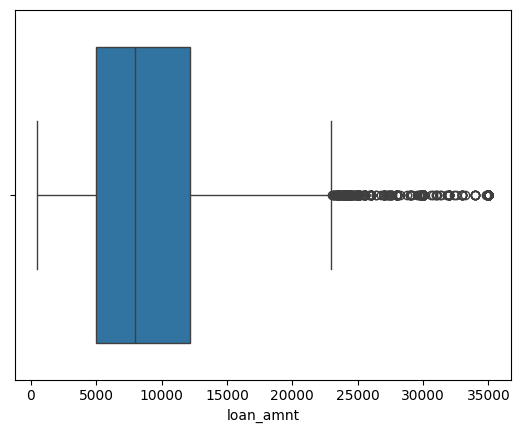

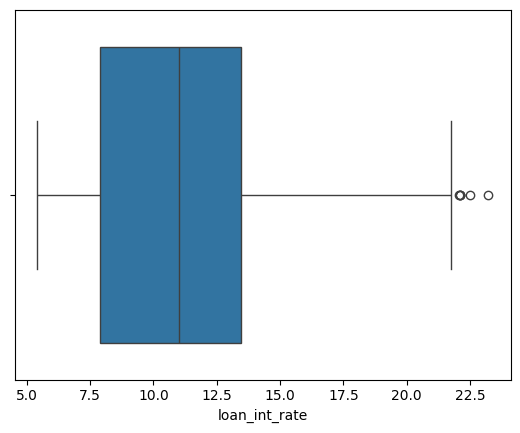

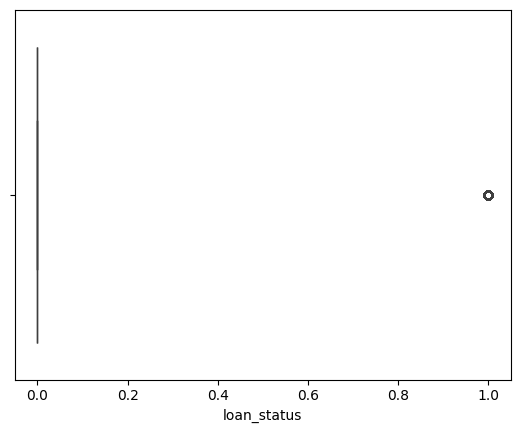

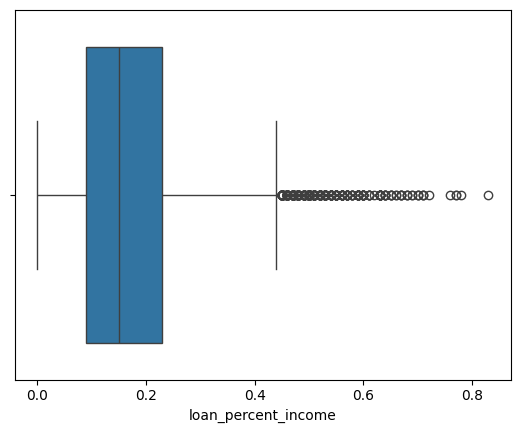

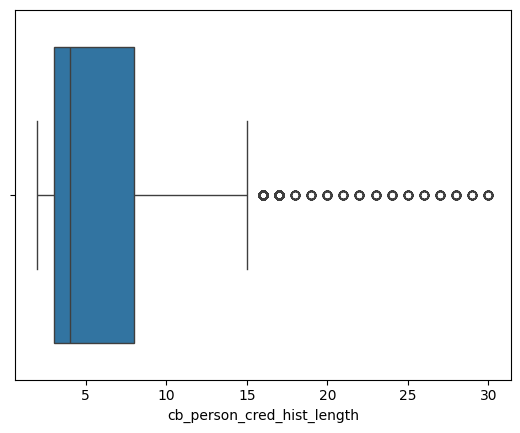

In [185]:
numerical_col = df.select_dtypes(include='number').columns
for col in numerical_col:
  sns.boxplot(x=df[col])
  plt.show()


In [186]:
(df['person_age'] > 100).sum()

np.int64(5)

In [187]:
(df['person_emp_length']>60).sum()

np.int64(2)

In [188]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


**Correlation check**

See how strongly features are related to each other.
This helps us spot repeated or linked information.

<Axes: >

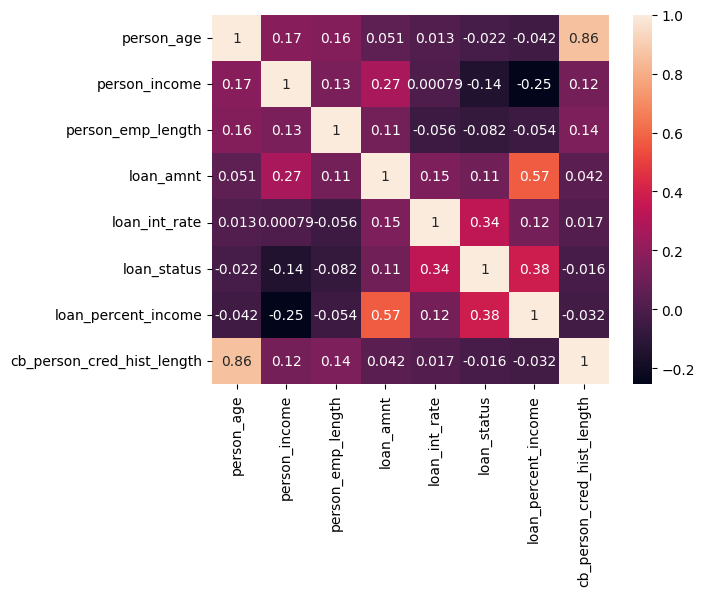

In [189]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

**Data Validation & Outlier Handling**

Here we clean the data properly.

We remove duplicate rows.

We remove rows with an impossible age or work experience.

We remove rows with zero or negative income and loan amount.

We check if the interest rate looks realistic.

We also flag rows where numbers don't add up correctly.


In [190]:
df_copy = df.copy()
print(f"Orginal Rows: {df_copy.shape[0]}")
#Removing duplicate rows
df_copy.drop_duplicates(inplace=True)
print(f"Rows After Removing Duplicate: {df_copy.shape[0]}")
#Remove the ages lessthan 18 or above 100
df_copy = df_copy[df['person_age']>=18]
df_copy = df_copy[df['person_age']<=100]
#Removing Employment length greater then age or extreme outliers(>60)
df_copy = df_copy[df_copy['person_emp_length'] <= df_copy['person_age']]
df_copy = df_copy[df_copy['person_emp_length']<=60]
#Remove the rows with zero or neagtive income and loan amount
df_copy = df_copy[df_copy['loan_amnt']>0]
#check if the interest rate looks realistic.
print("Loan intreset rate range from (min: 5.42 and max: 23.22)")

Orginal Rows: 32581
Rows After Removing Duplicate: 32416
Loan intreset rate range from (min: 5.42 and max: 23.22)


 **Features, Target & Train-Test Split**

We separate the data into input features and the target.
The target is whether the applicant defaulted or not.
We split the data into a training part and a testing part.
The model learns from the training part only.

In [191]:
X = df_copy.drop('loan_status',axis=1)
y = df_copy['loan_status']

In [192]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42,stratify=y)
#NOTE: We put stratify=y only in classification Data..

In [193]:
numerical_col = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

categorical_cols =  ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

**Handle Class Imbalance**

Very few people actually default in this data.
If we ignore this, the model may just favor the majority class.
We give more importance to the minority class during training.
This helps the model actually learn to spot defaulters.

In [194]:
neg, pos = np.bincount(y_train)
neg, pos

(np.int64(16558), np.int64(4561))

In [195]:
#0 -> no loan Repet Most in the data set which can create bais on nodel so
#we should calculate the scale_weight of the data or we can use class_weight=balance if there.
#1 -> yes loan
scale_weigths = neg/pos
scale_weigths

np.float64(3.630344222758167)

 **Data Preprocessing — Pipelines & Column Transformer**

Raw data is not ready for a model directly.
We need to prepare numeric and text columns differently.
We will build a Pipeline for each model.
We will use ColumnTransformer to apply different steps to different columns.

**Preprocessing for Logistic Regression**

Fill missing numeric values.
Scale numeric values, since this model is sensitive to scale.
Convert category columns into numbers using one-hot encoding.

In [196]:
#logistic Regressuon : impute + Scale numberic, imputer + one-not-encoding
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
preprocesser_lr = ColumnTransformer(
    transformers=[
        #pipeline for numerical cols
        ('num',Pipeline([
            ('imputer',SimpleImputer(strategy='median')),
            ('scaler',StandardScaler())
        ]),numerical_col),
        #Pipeline fro the categorical cols
        ('cat',Pipeline([
            ('imputer',SimpleImputer(strategy="constant",fill_value='missing')),
            ('onehot',OneHotEncoder(handle_unknown='ignore'))
        ]),categorical_cols)
    ])

**Preprocessing for XGBoost**

Fill missing numeric values.
No scaling needed here, since tree models don't need it.
Convert category columns into numbers using one-hot encoding.

In [197]:
#XGBoost: Impute numeric only (No Scaling), impute + One - Hot Encoding

preprocessor_xg = ColumnTransformer(
    transformers=[
        #Pipeline - for numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median'))
        ]), numerical_col),

        #Pipeline - for Categorical cols.
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ])

**Preprocessing for Randomforestclassifier**

In [198]:
preprocesser_rf = ColumnTransformer(
    transformers=[
    ("num", Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
]), numerical_col),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_cols),
])


**Preprocessing for Adaboost**

In [199]:
preprocesser_Ad = ColumnTransformer(
    transformers=[
    ("num", Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
]), numerical_col),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_cols),
])


**Evaluation Helper Function**

We build one common function to check any model's performance.
It will show accuracy, precision, recall, F1 score, and more.
It will also show a confusion matrix and a precision-recall curve.

In [209]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,precision_recall_curve
def evaluate_model(model_name,model,X_test,y_test,threshold=0):
  y_pred_prob = model.predict_proba(X_test)[:,1]
  if threshold:
    y_pred = (y_pred_prob>threshold).astype(int)
  else:
    y_pred = model.predict(X_test)
   #Metrics
  accuracy     = accuracy_score(y_test, y_pred)    #Overall model's preformance
  precision    = precision_score(y_test, y_pred)   #When the model says 1, how oftenly is it actually 1.
  recall       = recall_score(y_test, y_pred)      #of the actual 1 how many did the model catches
  f1           = f1_score(y_test, y_pred)          #Harmonic mean of precision and recall

  conf_matrix   = confusion_matrix(y_test, y_pred)
  class_report  = classification_report(y_test, y_pred)

  print(f"{model_name} Metrics:")
  if threshold is not None: # Only print threshold if provided
    print(f"Used Threshold : {threshold:.2f}")
  print(f"Accuracy : {accuracy:.2f}")
  print(f"Precision : {precision:.2f}")
  print(f"Recall : {recall:.2f}")
  print(f"F1 : {f1:.2f}")
  print()
  print(f"{model_name} Classification Report:")
  print(class_report)


  #Plotting confusion matrix
  sns.heatmap(conf_matrix, annot=True, fmt="d")
  plt.title(f"{model_name} Confusion Matrix")
  plt.ylabel("Actual Values")
  plt.xlabel("Predicted Values")
  plt.show()


  #Plotting ROC-AUC curve
  precisions, recalls, threshold = precision_recall_curve(y_test, y_pred_prob)
  plt.plot(recalls, precisions)
  plt.xlabel("Recall")
  plt.ylabel("Precision")
  plt.title(f"{model_name} Precision-Recall Curve")
  plt.show()

**Stratified Cross-Validation**

One single train-test split may not be reliable.
We split the training data into five folds instead.
Each fold keeps the same default vs repaid ratio.
We check the model's score across all folds.

In [201]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {'roc_auc':'roc_auc', 'accuracy':'accuracy', 'precision':'precision', 'recall':'recall', 'f1':'f1'}

In [202]:
#Logistic Regression
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocesser_lr),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

In [203]:
from xgboost import XGBClassifier
xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.1,
        scale_pos_weight=scale_weigths,random_state=42
    ))
])

In [204]:
from sklearn.ensemble import RandomForestClassifier
rf_cv_pipeline = Pipeline([
    ('preprocessor', preprocesser_rf),
    ('classifier', RandomForestClassifier(
        n_estimators=300, max_depth=5,
        class_weight="balanced",random_state=42
    ))
])

In [205]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
ad_cv_pipeline = Pipeline([
    ('preprocessor', preprocesser_Ad),
    ('classifier', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, class_weight="balanced"),
        n_estimators=300,learning_rate=0.1,random_state=42
    ))
])

In [206]:
for cv_name, pipe in [("Logistic Regression", lr_cv_pipeline),
                      ("XGBoost", xgb_cv_pipeline),('Random Forest',rf_cv_pipeline),('Adabost',ad_cv_pipeline)]:

                      cv_results = cross_validate(pipe, X_train , y_train, cv=cv, scoring=scoring, n_jobs=-1)

                      print(cv_name)
                      print(f"ROC-AUC : {cv_results['test_roc_auc'].mean()}")
                      print(f"Accuracy : {cv_results['test_accuracy'].mean()}")
                      print(f"Precision : {cv_results['test_precision'].mean()}")
                      print(f"Recall : {cv_results['test_recall'].mean()}")
                      print(f"F1 : {cv_results['test_f1'].mean()}")
                      print()


Logistic Regression
ROC-AUC : 0.8713404164641778
Accuracy : 0.8110233618747266
Precision : 0.5436005160273509
Recall : 0.7792147057128033
F1 : 0.6404194397951647

XGBoost
ROC-AUC : 0.9400626316909777
Accuracy : 0.9114067130576424
Precision : 0.7989063362718659
Recall : 0.7886418881266694
F1 : 0.7936443323273267

Random Forest
ROC-AUC : 0.8996474728969079
Accuracy : 0.8766987151888289
Precision : 0.6970808439453957
Recall : 0.7590455121923099
F1 : 0.726719778972781

Adabost
ROC-AUC : 0.7891491833180054
Accuracy : 0.8310527127777897
Precision : 0.6987712367690511
Recall : 0.3834656809054399
F1 : 0.4944195091894608



**Baseline Model — Logistic Regression**

We start with a simple model first.
This becomes our benchmark to beat.
We train it and check its score on the test data.

In [207]:
from sklearn.pipeline import Pipeline
baseline_model = Pipeline([
    ('preprocessor', preprocesser_lr),
    ('classifier', LogisticRegression(class_weight= "balanced"))
])
baseline_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier', LogisticRegression(class_weight='balanced'))])

Baseline Logistic Model Metrics:
Used Threshold : 0.00
Accuracy : 0.82
Precision : 0.55
Recall : 0.78
F1 : 0.65

Baseline Logistic Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      8157
           1       0.55      0.78      0.65      2246

    accuracy                           0.82     10403
   macro avg       0.74      0.80      0.76     10403
weighted avg       0.85      0.82      0.83     10403



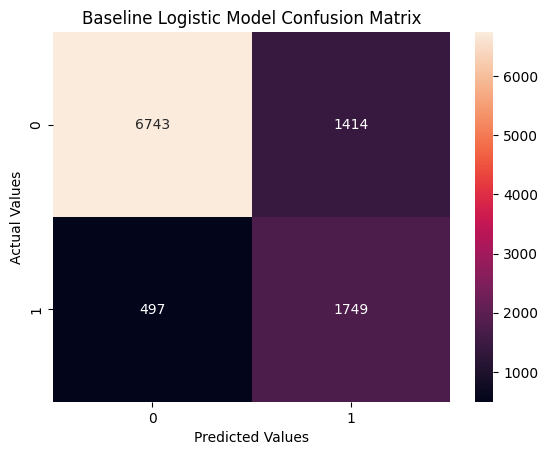

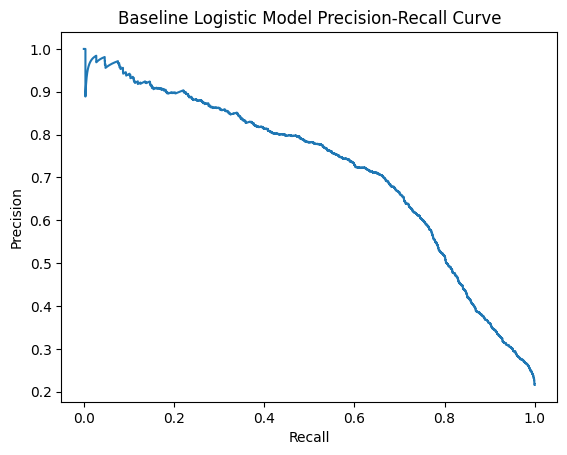

In [211]:
evaluate_model("Baseline Logistic Model", baseline_model ,X_test, y_test)

**Model Randomforest**

In [215]:
from sklearn.pipeline import Pipeline
rf_pipeline = Pipeline([
    ('preprocessor', preprocesser_rf),
    ('classifier', RandomForestClassifier(n_estimators=300, class_weight="balanced",
        random_state=42, n_jobs=-1))
])
rf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=300, n_jobs=-1,
                                        random_state=42))])

Random Forest Model Metrics:
Used Threshold : 0.00
Accuracy : 0.93
Precision : 0.98
Recall : 0.71
F1 : 0.82

Random Forest Model Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96      8157
           1       0.98      0.71      0.82      2246

    accuracy                           0.93     10403
   macro avg       0.95      0.85      0.89     10403
weighted avg       0.94      0.93      0.93     10403



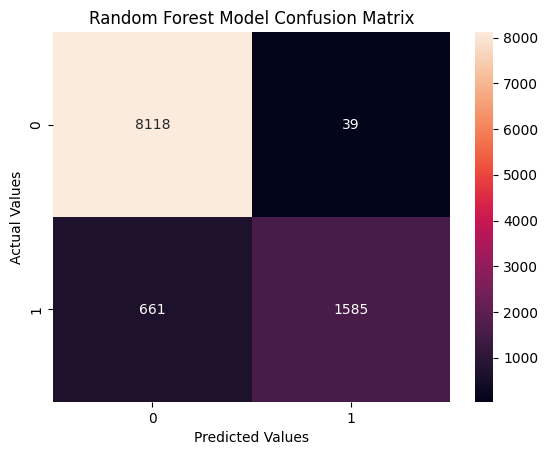

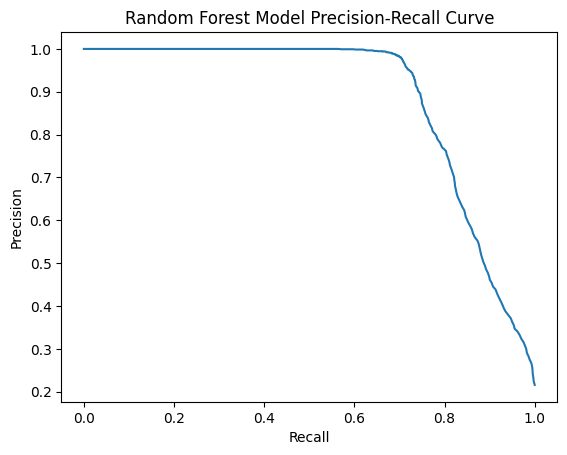

In [217]:
evaluate_model("Random Forest Model", rf_pipeline ,X_test, y_test)

**Model Adaboost**

In [218]:
Ad_pipeline = Pipeline([
    ('preprocessor', preprocesser_Ad),
    ('classifier', AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, class_weight="balanced"),
        n_estimators=200,
        learning_rate=0.5,
        random_state=42,))
])
Ad_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 AdaBoostClassifier(estimator=DecisionTreeClassifier(class_weight='balanced',
                                                                     max_depth=1),
                                    learning_rate=0.5, n_estimators=200,
                                    random_state=42))])

Ada boost Model Metrics:
Used Threshold : 0.00
Accuracy : 0.83
Precision : 0.71
Recall : 0.39
F1 : 0.50

Ada boost Model Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.96      0.90      8157
           1       0.71      0.39      0.50      2246

    accuracy                           0.83     10403
   macro avg       0.78      0.67      0.70     10403
weighted avg       0.82      0.83      0.81     10403



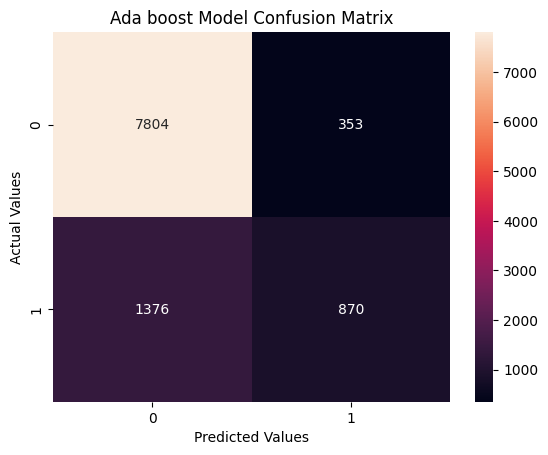

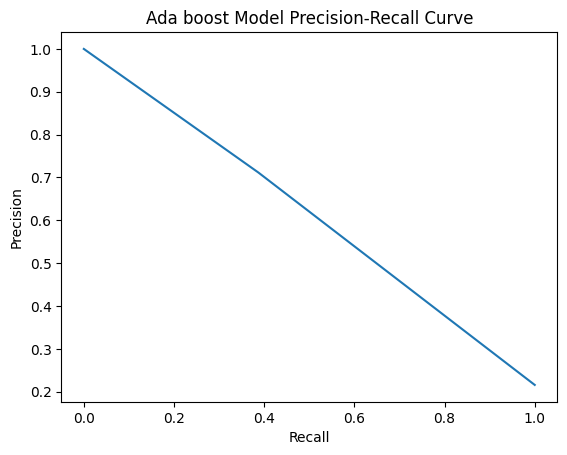

In [219]:
evaluate_model("Ada boost Model", Ad_pipeline ,X_test, y_test)

 **XGBoost Hyperparameter Tuning**

Now we move to a stronger model, XGBoost.
A model has many settings called hyperparameters.
We search for the best combination of these settings.
We use cross-validation while searching, so the result is reliable.

In [212]:
xg_model = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(learning_rate=0.1,
        scale_pos_weight=scale_weigths,random_state=42))
])
xg_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [213]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

param_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth" : randint(3,9),
    "classifier__learning_rate" : uniform(0.01, 0.5),
    "classifier__subsample": uniform(0.6,0.4), #Rows sampling
    "classifier__colsample_bytree" :uniform(0.6,0.4), #column sampling
    "classifier__min_child_weight": randint(1, 10),
    "classifier__gamma": uniform(0 , 5)
}
# lower gamma -> more splits -> complex tree -> higher overfitting risk
# higher gamma -> less splits ->  simpler tree -> low overfitting

In [214]:
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7f2d32805950>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7f2d58b852b0>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7f2d32805590>},
                   scoring='average_precision', verbose=1)

In [220]:
print(f"Score after performing Tunning {random_search.best_score_:.2f}")

Score after performing Tunning 0.90


In [221]:
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.8830262741080731),
 'classifier__gamma': np.float64(0.5126735929194726),
 'classifier__learning_rate': np.float64(0.044941735492239725),
 'classifier__max_depth': 6,
 'classifier__min_child_weight': 6,
 'classifier__n_estimators': 513,
 'classifier__subsample': np.float64(0.8287722658451586)}

**Compare Both Models Side by Side**

We now compare Logistic Regression and XGBoost.
We look at their scores together in one table.
This helps us pick the better performing model.

Logistic Regression Metrics:
Used Threshold : 0.00
Accuracy : 0.82
Precision : 0.55
Recall : 0.78
F1 : 0.65

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      8157
           1       0.55      0.78      0.65      2246

    accuracy                           0.82     10403
   macro avg       0.74      0.80      0.76     10403
weighted avg       0.85      0.82      0.83     10403



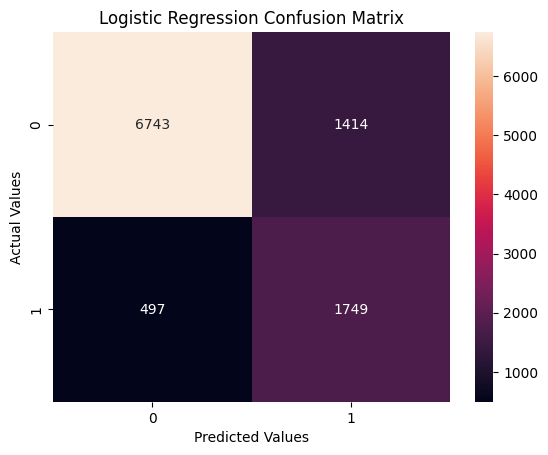

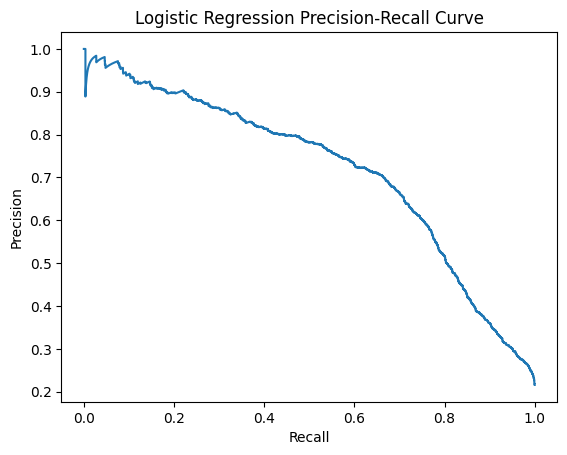

In [222]:
evaluate_model("Logistic Regression", baseline_model, X_test, y_test)

XGBoost Metrics:
Used Threshold : 0.00
Accuracy : 0.92
Precision : 0.83
Recall : 0.80
F1 : 0.81

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.96      0.95      8157
           1       0.83      0.80      0.81      2246

    accuracy                           0.92     10403
   macro avg       0.89      0.88      0.88     10403
weighted avg       0.92      0.92      0.92     10403



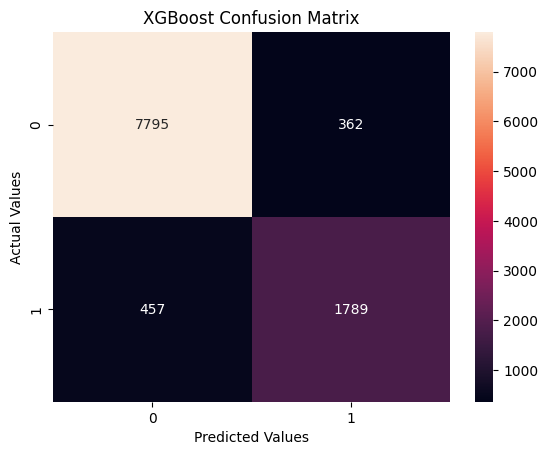

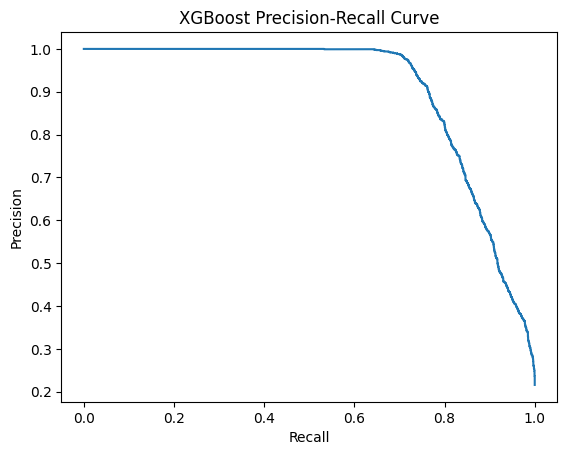

In [223]:
#Passing the XGBoost model after performing Hyperparameter Tuning
evaluate_model("XGBoost", random_search, X_test, y_test)

Random Forest Model Metrics:
Used Threshold : 0.00
Accuracy : 0.93
Precision : 0.98
Recall : 0.71
F1 : 0.82

Random Forest Model Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96      8157
           1       0.98      0.71      0.82      2246

    accuracy                           0.93     10403
   macro avg       0.95      0.85      0.89     10403
weighted avg       0.94      0.93      0.93     10403



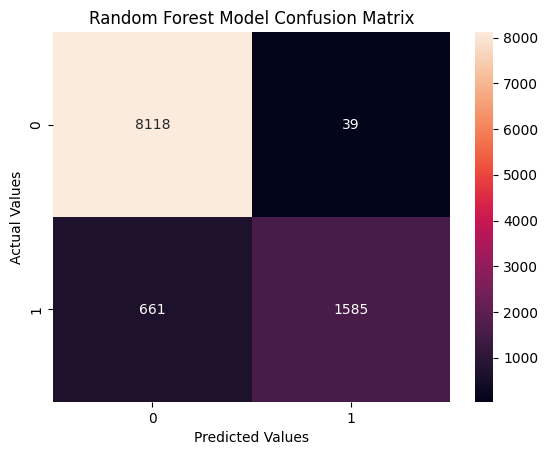

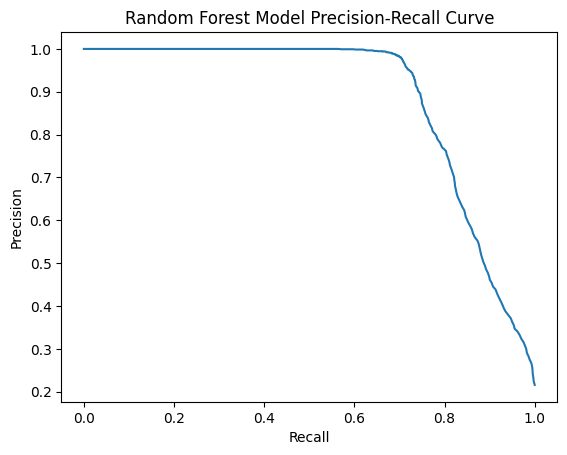

In [224]:
evaluate_model("Random Forest Model", rf_pipeline ,X_test, y_test)

Ada boost Model Metrics:
Used Threshold : 0.00
Accuracy : 0.83
Precision : 0.71
Recall : 0.39
F1 : 0.50

Ada boost Model Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.96      0.90      8157
           1       0.71      0.39      0.50      2246

    accuracy                           0.83     10403
   macro avg       0.78      0.67      0.70     10403
weighted avg       0.82      0.83      0.81     10403



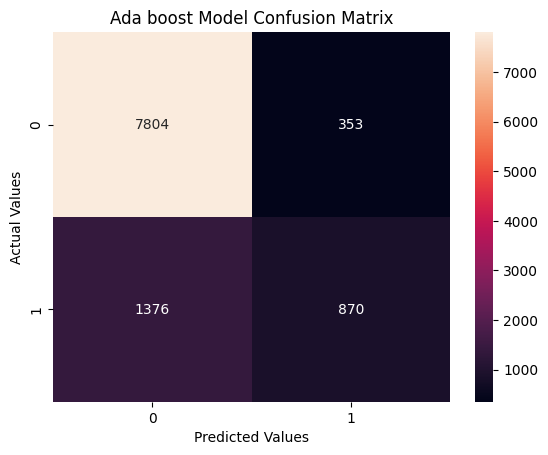

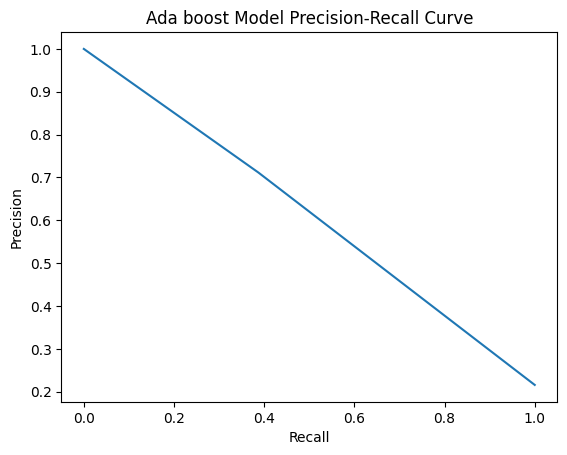

In [225]:
evaluate_model("Ada boost Model", Ad_pipeline ,X_test, y_test)

**Optimizing the Classification Threshold**

The model gives a probability, not a direct yes or no.
We decide a cut-off point to turn it into a decision.
We check different cut-off points and pick the best one.

XGBoost Metrics:
Used Threshold : 1.00
Accuracy : 0.78
Precision : 0.00
Recall : 0.00
F1 : 0.00

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.78      1.00      0.88      8157
           1       0.00      0.00      0.00      2246

    accuracy                           0.78     10403
   macro avg       0.39      0.50      0.44     10403
weighted avg       0.61      0.78      0.69     10403



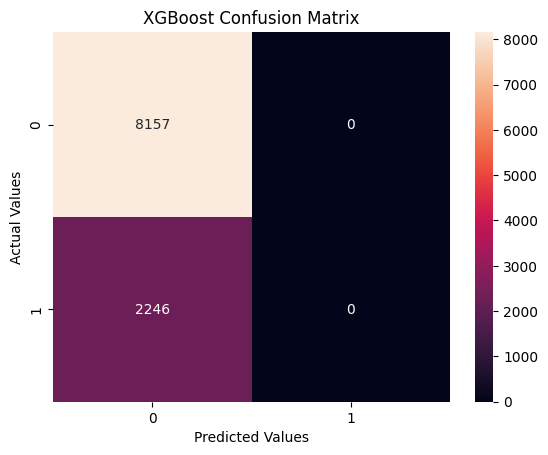

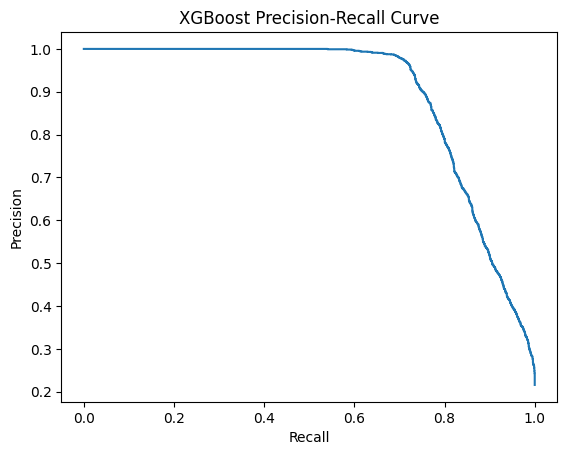

In [226]:
#Get the prob. of class 1 from XGBoost
prob = xg_model.predict_proba(X_test)[:, 1]

#For each threshold calculate Precision and Recall
precisions, recalls , thresholds = precision_recall_curve(y_test, prob)


#Calculate F1 score for each threshold
f1 = 2 * (precisions-recalls) / (precisions + recalls + 1e-9)

#Get the threshold that produces the highest f1-score
best = np.argmax(f1[:-1])
best_threshold = thresholds[best]

#Evaluate the XGBoost model using that threshold.
evaluate_model("XGBoost", xg_model, X_test, y_test, best_threshold)

 **Probability Calibration**

Sometimes a model's probability doesn't mean what it says.
For example, 30% risk should truly mean a 30% chance.
We check this with a calibration plot.
We fix it if the probabilities are off.

In [227]:
"""
Methods by which we can fix the poorly calibrated model.
1. Platt Scaling/ Sigmoid -> Adjust the probabilites using a sigmoid curve.
2. Isotonic Regression -> Learn a flexible mapping from old prob. - better prob. (non-linear calibartion)
3. Temperature Scaling -> Adjust the confidence of neural-network predictions using one temperature
"""

'\nMethods by which we can fix the poorly calibrated model.\n1. Platt Scaling/ Sigmoid -> Adjust the probabilites using a sigmoid curve.\n2. Isotonic Regression -> Learn a flexible mapping from old prob. - better prob. (non-linear calibartion)\n3. Temperature Scaling -> Adjust the confidence of neural-network predictions using one temperature\n'

In [228]:
#1. Calibrated XGBoost model
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(
    best_model,
    method="sigmoid",
    cv=5
)

calibrated_model.fit(X_train, y_train)

CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer...
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.044941735492239725),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=6,
                                                                max_leaves=None,
                                                                min_child_weight=6,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=513,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]))

In [229]:
#2. Get probabilites
uncalibrated = xg_model.predict_proba(X_test)[:,1]
calibrated = calibrated_model.predict_proba(X_test)[:,1]

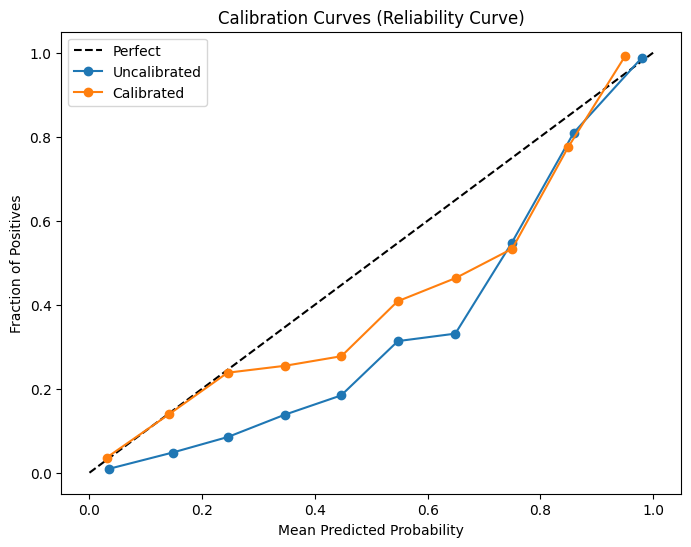

In [232]:
# Calculate calibration curve for uncalibrated model predictions
actual_uncal, predicted_uncal = calibration_curve(y_test, uncalibrated, n_bins=10)

# Plot calibration curves side-by-side
plt.figure(figsize=(8, 6))
plt.plot([0,1], [0,1], 'k--', label="Perfect")
plt.plot(
    predicted_uncal,
    actual_uncal,
    "o-",
    label = "Uncalibrated"
)

plt.plot(
    predicted_cal,
    actual_cal,
    "o-",
    label = "Calibrated"
)
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Calibration Curves (Reliability Curve)")
plt.legend()
plt.show()

**SHAP Interpretation — Global & Local**

SHAP helps us understand why the model makes a decision.
It is a way of explaining a "black box" model.

In [233]:
import shap
#2. Get the Trained XGBoost classifier model out of the pipeline.
xgb_classifier = xg_model.named_steps['classifier']

In [234]:
#3. Transform X_test using the same preprocessing used for training.
X_test_transformed = xg_model.named_steps['preprocessor'].transform(X_test)

In [235]:
#4. Get feature names after one-hot enocding , so plots are readable
feature_names = xg_model.named_steps['preprocessor'].get_feature_names_out()

In [236]:
#5. Convert to a dataframe for cleaner SHAP plots
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)

In [237]:

#6. Create SHAP explainer built for tree-based model
explainer = shap.TreeExplainer(xgb_classifier)

In [238]:
#7. Calculate SHAP values for every row in the test set
shap_values = explainer.shap_values(X_test_df)
shap_values

array([[ 0.04399857,  0.04263779,  0.09801882, ..., -0.00785964,
        -0.00805606,  0.        ],
       [-0.20236444, -1.0845456 , -0.15912656, ..., -0.00853321,
        -0.00331043,  0.        ],
       [-0.02769572,  0.7397295 ,  0.03290172, ..., -0.00770894,
         0.02737925,  0.        ],
       ...,
       [ 0.10679983, -1.1099346 , -0.11794779, ..., -0.00907352,
        -0.00309707,  0.        ],
       [ 0.02065774,  0.45021787, -0.21737243, ..., -0.00679155,
        -0.00529028,  0.        ],
       [-0.01330218, -0.6000857 , -0.11346805, ..., -0.00781418,
         0.00179192,  0.        ]], dtype=float32)

Global explanation

This shows which features matter most overall.
It also shows if a feature increases or decreases risk.

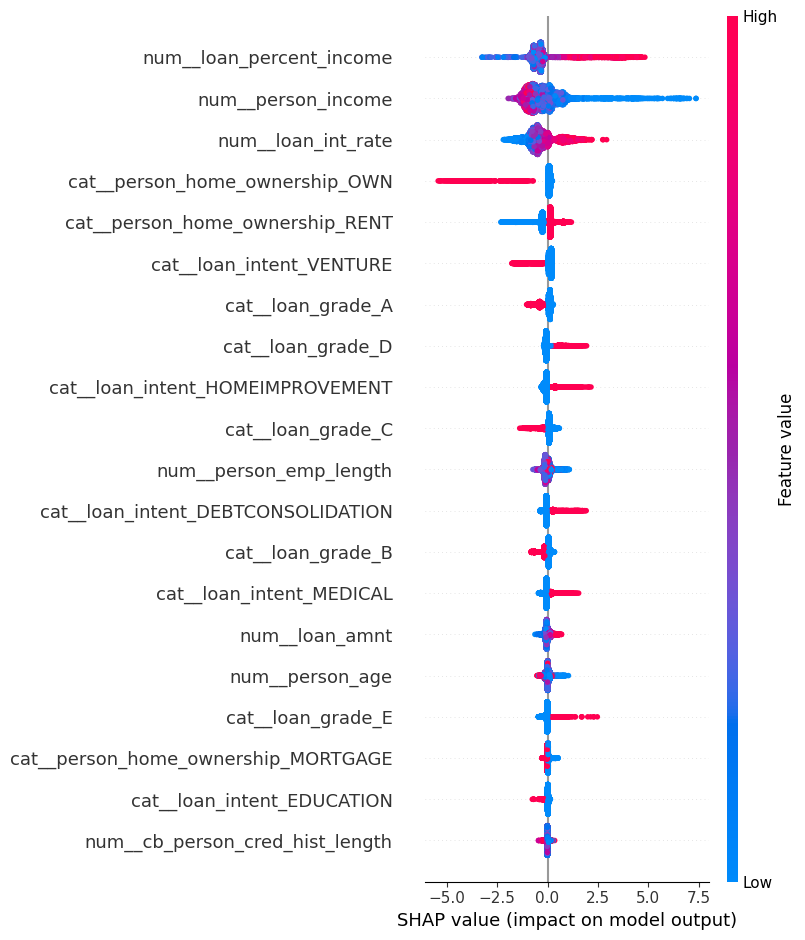

In [239]:
shap.summary_plot(shap_values, X_test_df)

Local explanation

This shows why one specific applicant got their score.
It breaks the score down feature by feature.

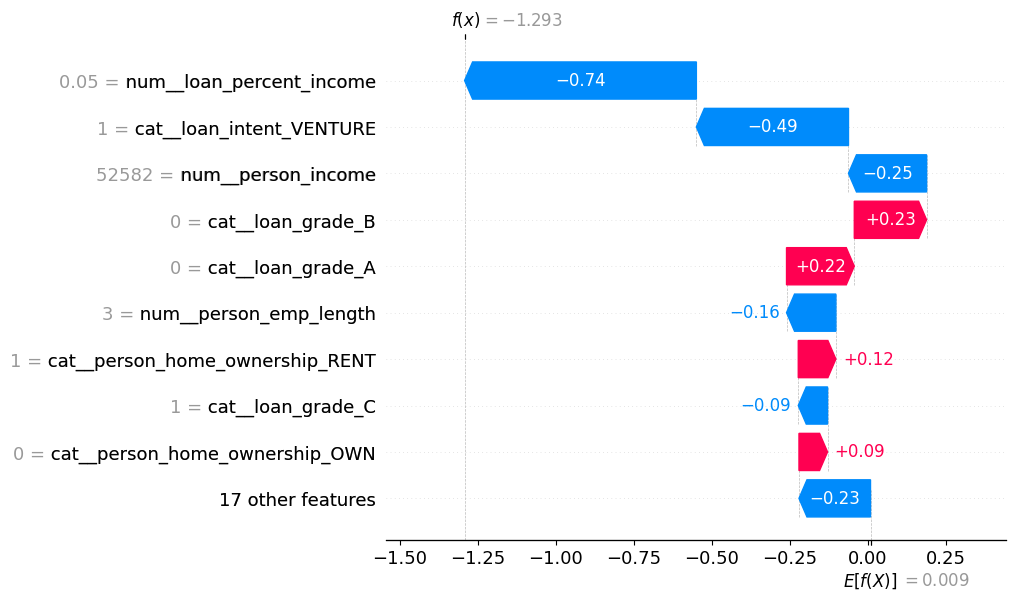

In [240]:
# 1. Pick one row to explain, e.g. the 5th applicant in the test set
row_index = 5

#2. Draw a waterfall plot showing how each feature pushed the prediction up or down.
shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,
        data = X_test_df.iloc[row_index],
        feature_names = feature_names
    )
)

 Analyzing False Positives & False Negatives

The model will not be perfect.
False positives are safe people wrongly marked risky.
False negatives are risky people wrongly marked safe.
We study these cases to understand where the model struggles.

In [241]:
#Get predictions from the best performing XGBoost model on the test set
y_pred = random_search.predict(X_test)

In [242]:
#Create a dataframe to easily compare the actual and predicted values
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred


In [243]:
#Identify False Positive : Model Predicted 1, but the actual was 0
false_positive = result_df[(result_df['actual']== 0) & (result_df['predicted']== 1)]

#Identify False Negative : Model Predicted 0, but the actual was 1
false_negative = result_df[(result_df['actual']== 1) & (result_df['predicted']== 0)]

In [244]:
print(f"False Positive : {len(false_positive)}")
print(f"False Negative : {len(false_negative)}")


False Positive : 362
False Negative : 457


 Save the Final Model


Once we are happy with the model, we save it.
We also save the settings it needs, like the chosen threshold.
This saved file can now be used in a real application.

In [245]:
import joblib

joblib.dump(calibrated_model, "credit_risk_model.pkl")

['credit_risk_model.pkl']

In [246]:
joblib.dump(best_threshold, "best_threshold.pkl")

['best_threshold.pkl']